In [1]:
# Student Name: Amelia Hamulewicz
# Student Number: C00296605
# Date: 12/11/2026

# Exploring Student Habits and Academic Performance
As a student, I chose to look at sleep, screen time and study hours, and how they relate to students' grades. These are habits that are part of everyday student life.

**1. Logistic Regression:** Based on their sleep, screen time and study hours, does a student have a CGPA of 3.0 or above? <br>
**2. Decision Tree:** What combination of sleep, screen time and study hours is linked to a higher CGPA? <br>
**3. Naive Bayes:** How likely is a student to have a higher CGPA based on their daily habits? <br>
**4. Confusion Matrix + Model Performance:** How often did the models get students' performance right or wrong? <br>
**5. PCA:** Can PCA combine sleep hours and sleep quality into one summary? <br>

In my examples, **higher CGPA means 3.0 or above**. CGPA is the student's overall grade average, rather than a score from one exam. The cutoff of 3.0 is my project choice, not an official pass mark.


### Lets begin with the standard imports:


In [2]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.decomposition import PCA
from sklearn.tree import DecisionTreeClassifier, plot_tree
from sklearn.naive_bayes import GaussianNB
from sklearn.dummy import DummyClassifier
from sklearn.metrics import (ConfusionMatrixDisplay, accuracy_score,
                             precision_score, recall_score, f1_score)
plt.style.use('seaborn-v0_8-whitegrid')

### Loading the dataset
Now lets load the [Student Sleep, Screen Time & Academic Performance dataset](https://www.kaggle.com/datasets/aamir28/student-sleep-screen-time-and-academic-performance) by Muhammad Aamir, that I found on Kaggle. [1]

The dataset has **500 rows and 25 columns**. Each row is one student example. The records are synthetic, which means they were generated rather than collected from real students.

I will use **avg_sleep_hours_weekday**, **daily_screen_time_hours** and **weekly_study_hours** as the inputs. I will use **cgpa** to create the answer I want to predict.


In [3]:
# Load the dataset
students = pd.read_csv('student_sleep_screen_time_academic_performance.csv')

# Show the first five rows and the dataset size
display(students.head())
print('Dataset size:', students.shape)


,student_id,age,gender,year_of_study,major_category,residence_type,chronotype,avg_bedtime_hour,avg_sleep_hours_weekday,weekend_sleep_delta_hours,...,naps_per_week,sleep_quality_score,exercise_days_per_week,energy_level,concentration_difficulty,weekly_study_hours,class_attendance_percent,has_part_time_job,semester_type,cgpa
0,STU2001,21,Male,3,Humanities,With Family,Early Bird,22.3,7.6,2.0,...,0,10.0,7,5.0,7.0,15.6,80.0,No,Spring,2.99
1,STU2002,20,Female,2,STEM,Dormitory,Intermediate,23.1,5.9,2.7,...,3,7.0,3,6.0,7.0,17.5,78.9,No,Summer,2.88
2,STU2003,20,Male,4,Social Sciences,With Family,Intermediate,23.4,8.4,1.8,...,1,9.0,2,5.0,1.0,19.0,69.7,Yes,Spring,3.15
3,STU2004,22,F,1,Humanities,Off-campus Apartment,Night Owl,0.9,5.1,2.4,...,3,6.0,4,3.0,7.0,7.3,59.1,No,Fall,2.27
4,STU2005,23,Female,4,Social Sciences,Off-campus Apartment,Early Bird,23.4,5.9,2.0,...,2,7.0,6,8.0,3.0,23.6,79.9,No,Summer,2.74


Dataset size: (500, 25)


### Checking the data
First, I will check for missing values and repeated student IDs. I will also look at the ranges of sleep, screen time, study hours and CGPA.

I will remove rows with missing CGPA values and add a column showing whether each student’s CGPA is 3.0 or above. Missing values in unused columns will be kept.


In [4]:
# Choose the columns used in this project
features = ['avg_sleep_hours_weekday', 'daily_screen_time_hours', 'weekly_study_hours']
selected = features + ['cgpa']

# Check for missing values and repeated student IDs
display(students[selected].isna().sum())
print('Repeated student IDs:', students['student_id'].duplicated().sum())

# Show summary statistics
display(students[selected].describe().round(2))

# Remove rows with missing CGPA
data = students.dropna(subset=['cgpa']).copy()

# Add 1 for CGPA of 3.0 or above, otherwise 0
data['higher_cgpa'] = (data['cgpa'] >= 3.0).astype(int)

# Show how many students remain and count each group
print('Rows after cleaning:', len(data))
display(data['higher_cgpa'].value_counts().sort_index())

avg_sleep_hours_weekday    0
daily_screen_time_hours    0
weekly_study_hours         0
cgpa                       7
dtype: int64

Repeated student IDs: 0


,avg_sleep_hours_weekday,daily_screen_time_hours,weekly_study_hours,cgpa
count,500.00,500.00,500.00,493.00
mean,6.61,5.83,16.57,2.83
std,1.44,2.05,6.93,0.33
min,1.50,0.50,0.00,1.89
25%,5.70,4.47,12.10,2.62
50%,6.60,5.80,16.30,2.85
75%,7.70,7.20,20.32,3.05
max,10.50,19.50,88.50,3.95


Rows after cleaning: 493


higher_cgpa
0    346
1    147
Name: count, dtype: int64

### Limitation found and fixed
Seven rows have missing CGPA values. I removed these rows because the answer is not recorded. This leaves **493 student examples**. The three input columns have no missing values.

Missing values in other columns will be kept because those columns are not needed. Some values are unusual, including **19.5 screen hours** per day and **88.5 study hours** per week. I will keep them because I cannot confirm they are errors, but they may affect the results.

### Preparing the training and test data
I will use 80% of the data to train the models and 20% to test how well they work.

`X` will contain the **3 habits**; sleep hours, screen time and study hours. `Y` will show whether the student’s **CGPA is 3.0 or above**: 1 for yes and 0 for no.

I will use the same data for all three models so I can compare their results fairly. I will also scale the inputs using only the training data because the hours are measured per day or per week.

Code adapted from: [03_multi-class-classification_starter.ipynb](https://github.com/gabrielsanchez/curriculum-ds/blob/main/notebooks/09-ml-classification/03_multi-class-classification_starter.ipynb) [2]


In [5]:
X = data[features]
Y = data['higher_cgpa']

# Use 80% for training and 20% for testing
# random_state makes the split repeatable
# stratify keeps similar proportions of both CGPA groups
Xtrain, Xtest, Ytrain, Ytest = train_test_split(
    X, Y, test_size=0.2, random_state=42, stratify=Y
)

# Learn how to scale the inputs from the training data
scaler = StandardScaler()
Xtrain_scaled = scaler.fit_transform(Xtrain)
Xtest_scaled = scaler.transform(Xtest)

# Show the number of students in each set
print('Training examples:', len(Xtrain))
print('Test examples:', len(Xtest))
print('Test students with CGPA 3.0 or above:', (Ytest == 1).sum())

# Show the percentage with CGPA of 3.0 or above in each set
print('Higher CGPA in training (%):', round(Ytrain.mean() * 100, 1))
print('Higher CGPA in testing (%):', round(Ytest.mean() * 100, 1))

Training examples: 394
Test examples: 99
Test students with CGPA 3.0 or above: 30
Higher CGPA in training (%): 29.7
Higher CGPA in testing (%): 30.3


## **1. Logistic Regression:** Based on their sleep, screen time and study hours, does a student have a CGPA of 3.0 or above?

The model predicts one answer for each student:

- **Yes (1):** CGPA is 3.0 or above.
- **No (0):** CGPA is below 3.0.

It uses sleep hours, screen time and weekly study hours to predict the answer.

I will check how often it gets this right and compare it with always answering “No, CGPA is below 3.0”.

Code adapted from: [Classification - Scikit-learn course](https://inria.github.io/scikit-learn-mooc/python_scripts/metrics_classification.html) [3], [Understanding Logistic Regression](https://www.geeksforgeeks.org/machine-learning/understanding-logistic-regression/) [4]

,Actual answer,Predicted answer
0,Yes,Yes
1,Yes,No
2,No,Yes
3,Yes,No
4,No,No
5,No,No
6,No,No
7,No,No
8,No,No
9,Yes,No


Logistic regression accuracy (%): 75.8
Baseline accuracy (%): 69.7
Difference from baseline (percentage points): 6.1


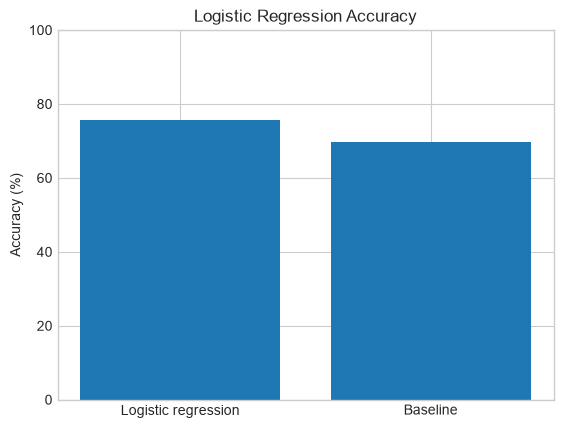

In [6]:
# Create and train the model [4]
logistic_model = LogisticRegression(max_iter=1000) 
logistic_model.fit(Xtrain_scaled, Ytrain)

# Predict the answers for the test students [4]
logistic_predictions = logistic_model.predict(Xtest_scaled)

# Compare the actual and predicted answers [3]
prediction_results = pd.DataFrame({
    'Actual answer': np.asarray(Ytest),
    'Predicted answer': logistic_predictions
})

# Show Yes and No instead of 1 and 0
prediction_results = prediction_results.replace({
    1: 'Yes',
    0: 'No'
})

display(prediction_results.head(10))

# For comparison, always predict the most common CGPA group [3]
baseline = DummyClassifier(strategy='most_frequent') 
baseline.fit(Xtrain, Ytrain)
baseline_predictions = baseline.predict(Xtest)

# Calculate how many predictions were correct (%) [3]
logistic_accuracy = accuracy_score(Ytest, logistic_predictions) * 100
baseline_accuracy = accuracy_score(Ytest, baseline_predictions) * 100

# Show the results [3]
print('Logistic regression accuracy (%):', round(logistic_accuracy, 1))
print('Baseline accuracy (%):', round(baseline_accuracy, 1))
print('Difference from baseline (percentage points):',
      round(logistic_accuracy - baseline_accuracy, 1))

# Compare the accuracy scores
plt.bar(['Logistic regression', 'Baseline'],
        [logistic_accuracy, baseline_accuracy])

plt.ylabel('Accuracy (%)')
plt.ylim(0, 100)
plt.title('Logistic Regression Accuracy')
plt.show()

### Conclusion
The model correctly predicted **yes** or **no** for 75.8% of the test students. Always answering **“No, CGPA is below 3.0”** for every student got **69.7%** right. Logistic regression performed **6.1 percentage points better**.

The habits helped predict the CGPA group, but this does not mean they caused the grades.

## **2. Decision Tree:** What combination of sleep, screen time and study hours is linked to a higher CGPA?
I will use a decision tree to predict yes or no. The diagram shows the rules it learns from the training students.

I chose to do a tree with the max depth of 3 as it keeps it small and readable.

`min_samples_leaf=20` keeps at least **20 training students** in each final group.

Code adapted from: [Scikit-Learn: Decision Trees](https://scikit-learn.org/stable/modules/tree.html) [5], [Decision Trees in Python Scikit-Learn: A Complete Guide For Beginners](https://medium.com/@techwithpraisejames/decision-trees-in-python-scikit-learn-a-complete-guide-for-beginners-15cb0540180f) [6]

Accuracy (%): 67.7


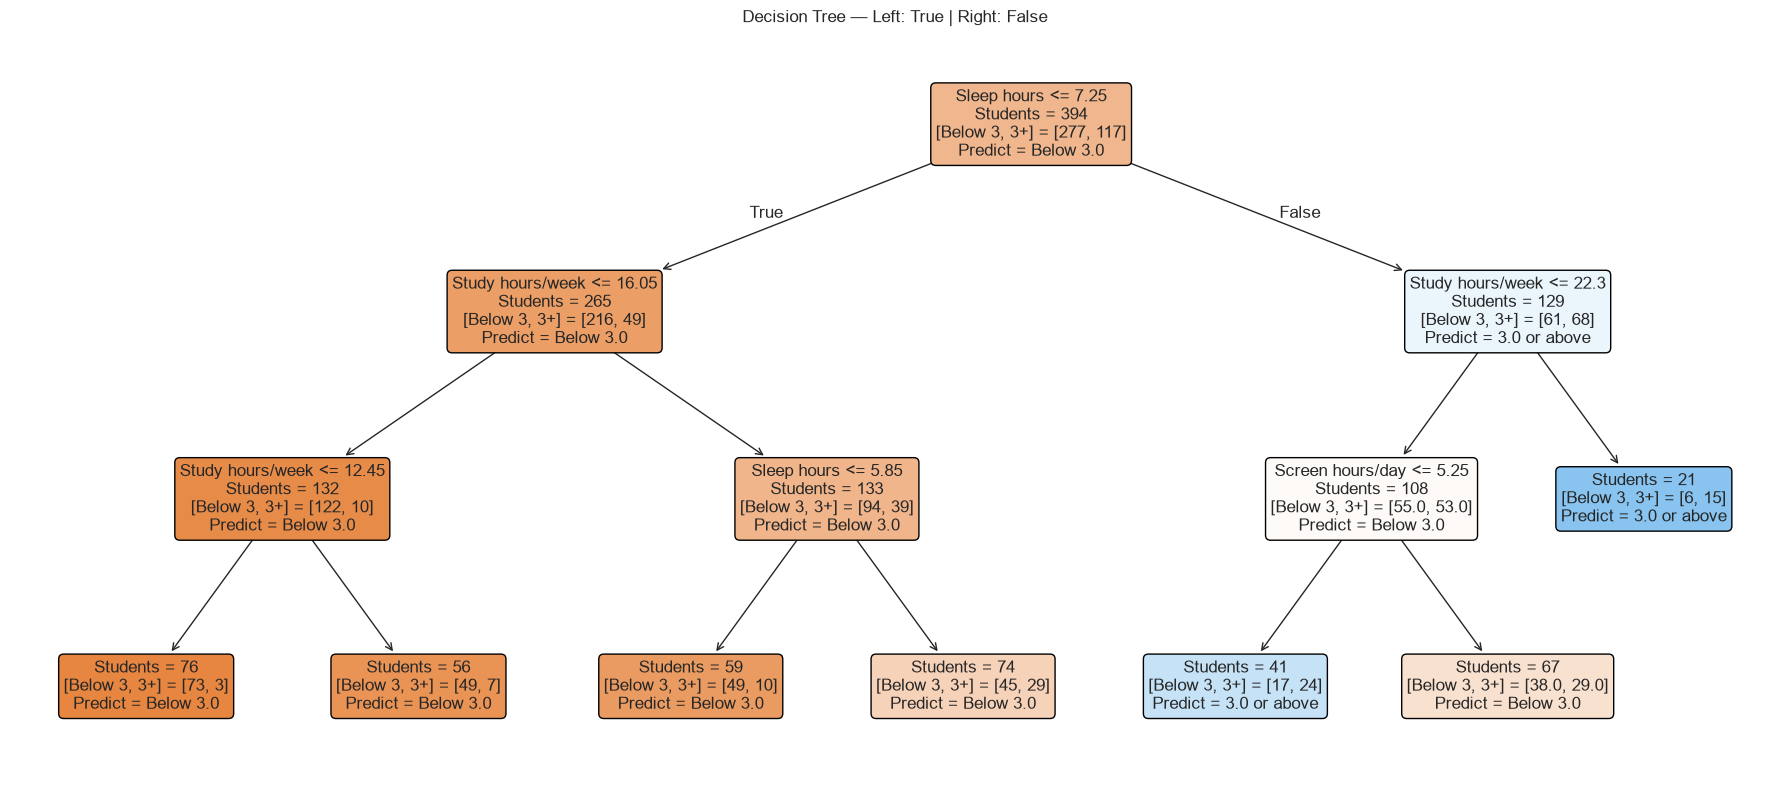

In [7]:
# Create a tree using controls shown in reference [5]
tree_model = DecisionTreeClassifier(max_depth=3, min_samples_leaf=20, random_state=42)
tree_model.fit(Xtrain, Ytrain)

# Check accuracy [6]
tree_predictions = tree_model.predict(Xtest)
print('Accuracy (%):',
      round(accuracy_score(Ytest, tree_predictions) * 100, 1))

# Draw the tree [6]
plt.figure(figsize=(18, 8))
boxes = plot_tree(
    tree_model,
    feature_names=['Sleep hours', 'Screen hours/day', 'Study hours/week'],
    class_names=['Below 3.0', '3.0 or above'],
    filled=True,
    rounded=True,
    impurity=False,
    fontsize=12
)

# Shorten the labels
for box in boxes:
    text = box.get_text()
    text = text.replace('samples =', 'Students =')
    text = text.replace('value =', '[Below 3, 3+] =')
    text = text.replace('class =', 'Predict =')
    box.set_text(text)

plt.title('Decision Tree — Left: True | Right: False')
plt.tight_layout()
plt.show()

### Conclusion

The decision tree predicted the correct CGPA group for **67.7%** of the test students.

One rule predicted CGPA 3.0 or above for students who slept more than **7.25 hours on weekdays** and studied more than **22.3 hours per week**. In the training data, **15 of the 21 students** in this group had a CGPA of 3.0 or above.

These habits did not guarantee a higher CGPA.

## **3. Naive Bayes:** How likely is a student to have a higher CGPA based on their daily habits?
Naive Bayes uses sleep, screen time and study hours to estimate a student's chance of having a CGPA below 3.0 or 3.0 and above.

It learns from the training students, then predicts the group with the higher estimated chance for each test student.

Naive Bayes looks at each habit separately within each CGPA group, then combines the information to estimate the student's group. It assumes the habits are independent, even though sleep, screen time and study hours may be related.

Code adapted from: [Naive Bayes Classification Tutorial using Scikit-learn](https://www.datacamp.com/tutorial/naive-bayes-scikit-learn#classifier-building-in-scikit-learn) [7], [In Depth: Naive Bayes Classification](https://github.com/jakevdp/PythonDataScienceHandbook/blob/8a34a4f653bdbdc01415a94dc20d4e9b97438965/notebooks/05.05-Naive-Bayes.ipynb) [8]


In [8]:
# Create and train the model # [7]
bayes_model = GaussianNB()
bayes_model.fit(Xtrain_scaled, Ytrain)

# Predict the test students
bayes_predictions = bayes_model.predict(Xtest_scaled) 

# Show actual and predicted answers for 8 students 
print('\nPredicted answers:')
print(bayes_predictions[:8])

print('Actual answers:')
print(Ytest.iloc[:8].to_numpy()) # [7]

# Check accuracy across all test students
bayes_accuracy = accuracy_score(Ytest, bayes_predictions)
print('\nAccuracy for all test students (%):',
      round(bayes_accuracy * 100, 1))

# Estimate the chance of each CGPA group
bayes_probabilities = bayes_model.predict_proba(Xtest_scaled)

print('\nEstimated chances for the same eight students:')
display(bayes_probabilities[:8].round(2)) # [8]

print('\nLeft = Below 3.0 | Right = 3.0 or above')


Predicted answers:
[1 0 1 0 0 1 0 0]
Actual answers:
[1 1 0 1 0 0 0 0]

Accuracy for all test students (%): 72.7

Estimated chances for the same eight students:


array([[0.41, 0.59],
       [0.67, 0.33],
       [0.36, 0.64],
       [0.56, 0.44],
       [0.76, 0.24],
       [0.44, 0.56],
       [0.61, 0.39],
       [0.72, 0.28]])


Left = Below 3.0 | Right = 3.0 or above


### Conclusion
Naive Bayes predicted the correct CGPA group for **72.7%** of the test students.

For the first student, the model estimated a **41% chance of CGPA below 3.0** and a **59% chance of CGPA 3.0 or above**. It chose the higher chance and predicted **1**, which matched the actual answer.

These chances are estimates. The 72.7% accuracy tells us how often the predicted groups were correct, not how accurate the estimated chances were.

## **4. Confusion Matrix:** How often did the models get students' performance right or wrong?

The confusion matrices show the correct predictions and the mistakes. Rows show the actual group and columns show the predicted group. The diagonal contains the correct predictions.

The top-right box shows students incorrectly predicted to have a CGPA of at least 3.0. The bottom-left box shows students with a CGPA of at least 3.0 that the model missed.

### Comparing the results

- **Accuracy:** how often the model was correct overall.
- **Precision:** when it predicted higher CGPA, how often it was right.
- **Recall:** how many actual higher-CGPA students it found.
- **F1:** combines precision and recall.

All four scores are percentages. Higher is better. Precision, recall and F1 refer to the group with CGPA of at least 3.0. If the model makes no higher-CGPA predictions, the code shows precision as zero.

Code adapted from: [Module 10: Regression and Classification - Predicting Outcomes](https://scds-aub.github.io/intro2ds/modules/data201/module10-regression#part-4-model-comparison-and-evaluation-20-minutes) [9], [Logistic Regression: The Threshold](https://ai.buas.nl/open-courses/introduction-to-ml/modules/3_modeling_and_evaluation/1_self_study/03_logistic_regression.html#the-threshold) [10]

In [9]:
# Calculate the scores for one model [9]
def performance(actual, predicted):
    scores = {
        'Accuracy (%)': accuracy_score(actual, predicted) * 100,
        'Precision (%)': precision_score(actual, predicted, zero_division=0) * 100,
        'Recall (%)': recall_score(actual, predicted, zero_division=0) * 100,
        'F1 (%)': f1_score(actual, predicted, zero_division=0) * 100
    }
    return scores


# Store each model's predictions
predictions = {
    'Baseline': baseline_predictions,
    'Logistic regression': logistic_predictions,
    'Decision tree': tree_predictions,
    'Naive Bayes': bayes_predictions
}

# Calculate the scores for each model
scores = {}

for name, predicted in predictions.items():
    scores[name] = performance(Ytest, predicted)

# Show one row per model
results = pd.DataFrame.from_dict(scores, orient='index')
display(results.round(1))

,Accuracy (%),Precision (%),Recall (%),F1 (%)
Baseline,69.7,0.0,0.0,0.0
Logistic regression,75.8,66.7,40.0,50.0
Decision tree,67.7,43.8,23.3,30.4
Naive Bayes,72.7,57.1,40.0,47.1


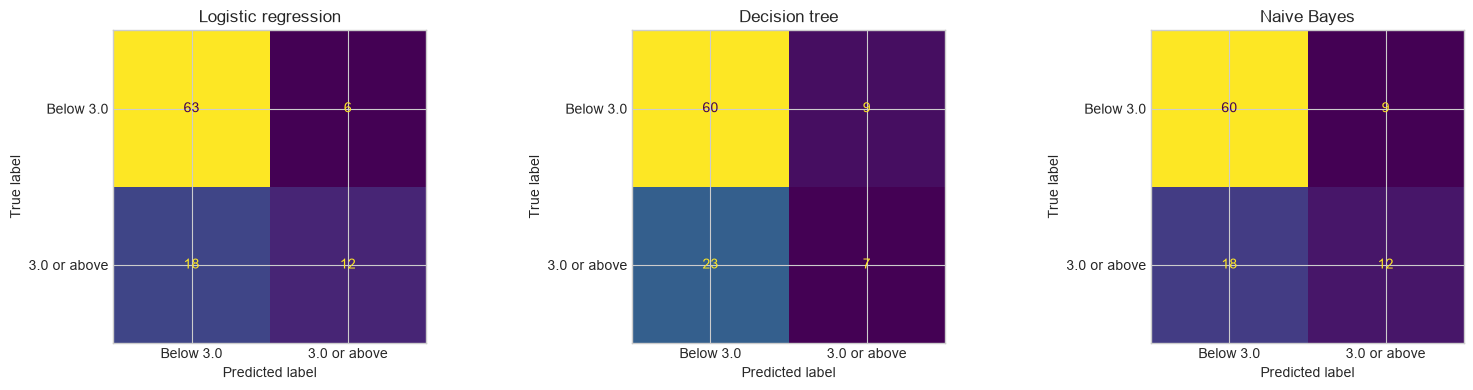

In [10]:
# Show confusion matrices for the three trained models
model_names = ['Logistic regression', 'Decision tree', 'Naive Bayes']

# Create three graph areas in one row [9]
fig, axes = plt.subplots(1, 3, figsize=(16, 4))

# Pair each graph area with a model [9]
for ax, name in zip(axes, model_names):

    # Draw the confusion matrix [10]
    ConfusionMatrixDisplay.from_predictions(
        Ytest,
        predictions[name],
        labels=[0, 1],
        display_labels=['Below 3.0', '3.0 or above'],
        ax=ax,  # Draw in the current Axes (graph area)
        colorbar=False
    )
    ax.set_title(name)

# Adjust spacing and show the graphs
plt.tight_layout()
plt.show()

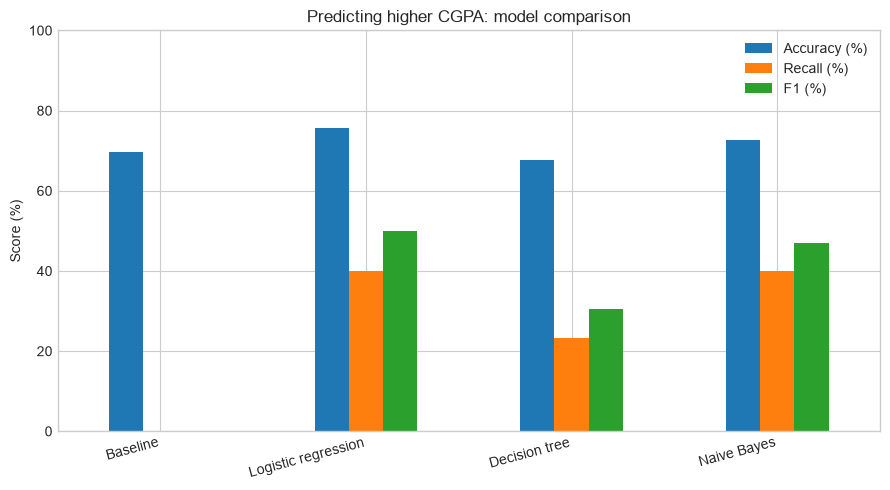

In [11]:
results[['Accuracy (%)', 'Recall (%)', 'F1 (%)']].plot.bar(figsize=(9, 5))
plt.ylabel('Score (%)')
plt.ylim(0, 100)
plt.xticks(rotation=15, ha='right')
plt.title('Predicting higher CGPA: model comparison')
plt.tight_layout()
plt.show()

### Comparing the scores
The table and graph above show the differences between the models. The next cell reports which model had the highest accuracy and F1.

In [12]:
model_results = results.drop(index='Baseline')
print('Highest accuracy among the models:', model_results['Accuracy (%)'].idxmax())
print('Highest F1 among the models:', model_results['F1 (%)'].idxmax())
print('Baseline accuracy (%):', round(baseline_accuracy, 1))

Highest accuracy among the models: Logistic regression
Highest F1 among the models: Logistic regression
Baseline accuracy (%): 69.7


### Conclusion
Logistic regression had the highest accuracy (**75.8%**) and F1 score (**50.0%**), making it the best overall performer in this test.

Logistic regression and Naive Bayes each correctly identified **12 of the 30 students with CGPA 3.0 or above**, giving a recall of **40%**. The decision tree identified **7 of the 30**, giving a recall of **23.3%**.

All three models missed many students with higher CGPA.

## **5. PCA:** Can PCA combine sleep hours and sleep quality into one summary?
I will use **sleep hours** and **sleep quality**. Students who sleep longer generally have higher sleep-quality scores in this dataset, so these two measurements share a pattern (see figure below).

PCA finds the direction where the students differ most. It uses this direction to turn the two measurements into one summary number for each student, called a principal component.

The first graph shows the two measurements and the direction PCA chooses. The second shows the students using just their new summary numbers. I will check how much of the original variation is kept. Variation means how much students' measurements differ.

Code adapted from: [Python Data Science Handbook — PCA](https://jakevdp.github.io/PythonDataScienceHandbook/05.09-principal-component-analysis.html) [11], [ML: Principal component analysis](https://csmastersuh.github.io/data_analysis_with_python_summer_2021/pca.html) [12]

Students used for PCA: 494
Variation kept (%): 87.3
Variation left out (%): 12.7


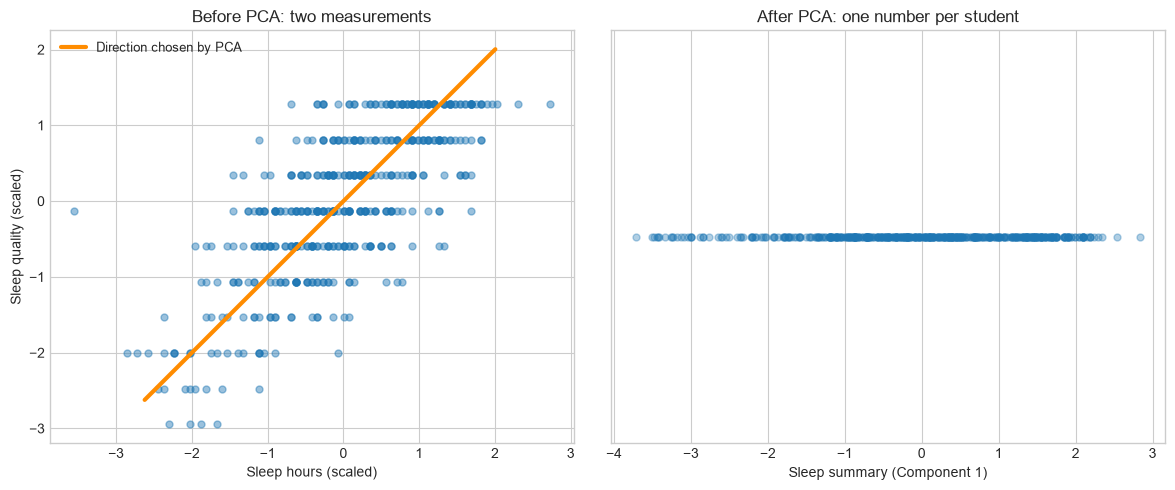

In [13]:
# Select the two measurements for this project
pca_columns = ['avg_sleep_hours_weekday', 'sleep_quality_score']
pca_data = students[pca_columns].dropna()
print('Students used for PCA:', len(pca_data))

# Put both measurements on a comparable scale
pca_scaler = StandardScaler()
pca_scaled = pca_scaler.fit_transform(pca_data)

# Combine the two measurements into one component [11, 12]
pca = PCA(n_components=1)
pca.fit(pca_scaled)
sleep_summary = pca.transform(pca_scaled)

# Find the percentage of variation kept [11]
variation_kept = pca.explained_variance_ratio_[0] * 100
print('Variation kept (%):', round(variation_kept, 1))
print('Variation left out (%):', round(100 - variation_kept, 1))

# Draw the direction chosen by PCA in the original scaled graph [11]
line_positions = np.linspace(sleep_summary.min(), sleep_summary.max(), 100)
pca_line = pca.inverse_transform(line_positions.reshape(-1, 1))

# Compare before and after PCA [12]
fig, axes = plt.subplots(1, 2, figsize=(12, 5))

# BEFORE: each student needs two numbers to locate their dot [11, 12]
axes[0].scatter(pca_scaled[:, 0], pca_scaled[:, 1], s=25, alpha=0.45)
axes[0].plot(pca_line[:, 0], pca_line[:, 1], color='darkorange',
             linewidth=3, label='Direction chosen by PCA')
axes[0].set_xlabel('Sleep hours (scaled)')
axes[0].set_ylabel('Sleep quality (scaled)')
axes[0].set_title('Before PCA: two measurements')
axes[0].set_aspect('equal', adjustable='box')
axes[0].legend(fontsize=9)

# AFTER: each student needs only one summary number [12]
axes[1].scatter(sleep_summary[:, 0], np.zeros(len(sleep_summary)),
                s=25, alpha=0.35)
axes[1].set_xlabel('Sleep summary (Component 1)')
axes[1].set_yticks([])
axes[1].set_ylim(-0.5, 0.5)
axes[1].set_title('After PCA: one number per student')
axes[1].grid(axis='y', visible=False)

plt.tight_layout()
plt.show()


### Conclusion
PCA combined **two measurements into one summary number per student** and kept **87.3%** of their variation across 494 students. It left out **12.7%** of the variation.

In the first graph, the dots follow a diagonal pattern: sleep hours and sleep quality generally increase together. The orange line shows the direction PCA uses to capture this shared pattern. It is a PCA direction, not a line predicting sleep quality.

In the second graph, each student's dot is placed using just one number. The up-and-down position has no meaning, so all dots are on one line and some overlap. Students near each other have similar summaries, although some differences between their original measurements have been lost.

PCA is useful here because it gives a simpler summary of two related measurements while keeping most of their variation. The summary is not measured in hours and does not predict grades.

### Overall conclusion

Logistic regression had the highest accuracy (**75.8%**) and F1 (**50.0%**). Naive Bayes reached **72.7%** accuracy, while the decision tree reached **67.7%**. The simple baseline scored **69.7%**.

Logistic regression and Naive Bayes each found **40.0%** of students with higher CGPA. They missed the other **60.0%**, so the predictions have limits even though their overall accuracy was higher than the baseline.

PCA used a separate set of 494 complete sleep records. It combined sleep hours and sleep quality into one component while keeping **87.3%** of their variation. The decision tree showed readable rules, but its overall accuracy was below the baseline.

The prediction results use 493 synthetic student examples and one training/test split. Different examples or settings could change the results. The CGPA cutoff of 3.0 is a project choice; students below it have not necessarily failed. The file does not establish when the habits were measured compared with the cumulative grades, so these results do not demonstrate predictions of future grades or prove cause and effect.

### References
1. Aamir, M. (n.d.) *Student Sleep, Screen Time & Academic Performance*. Kaggle. Available at: https://www.kaggle.com/datasets/aamir28/student-sleep-screen-time-and-academic-performance (Accessed: 17 November 2026).

2. gabrielsanchez (n.d.) *Multi-class classification starter notebook*. GitHub. Available at: https://github.com/gabrielsanchez/curriculum-ds/blob/main/notebooks/09-ml-classification/03_multi-class-classification_starter.ipynb (Accessed: 17 November 2026).

3. Inria (n.d.) *Classification*. Scikit-learn course. Available at: https://inria.github.io/scikit-learn-mooc/python_scripts/metrics_classification.html (Accessed: 17 November 2026).

4. GeeksforGeeks (2026) *Logistic regression in machine learning*. Available at: https://www.geeksforgeeks.org/machine-learning/understanding-logistic-regression/ (Accessed: 17 November 2026).

5. Scikit-learn developers (n.d.) *Decision trees*. Available at: https://scikit-learn.org/stable/modules/tree.html (Accessed: 22 November 2026).

6. James, P. (2026) *Decision trees in Python Scikit-Learn: A complete guide for beginners*. Medium. Available at: https://medium.com/@techwithpraisejames/decision-trees-in-python-scikit-learn-a-complete-guide-for-beginners-15cb0540180f (Accessed: 17 November 2026).

7. Awan, A.A. and Navlani, A. (2026) *Naive Bayes classification tutorial using Scikit-learn*. DataCamp. Available at: https://www.datacamp.com/tutorial/naive-bayes-scikit-learn (Accessed: 17 November 2026).

8. VanderPlas, J. (n.d.) *In depth: Naive Bayes classification*. Python Data Science Handbook. Available at: https://jakevdp.github.io/PythonDataScienceHandbook/05.05-naive-bayes.html (Accessed: 17 November 2026).

9. SCDS Course Materials (n.d.) *Module 10: Regression and classification – predicting outcomes*. Available at: https://scds-aub.github.io/intro2ds/modules/data201/module10-regression (Accessed: 17 November 2026).

10. Breda University of Applied Sciences (n.d.) *Logistic regression*. Introduction to Machine Learning. Available at: https://ai.buas.nl/open-courses/introduction-to-ml/modules/3_modeling_and_evaluation/1_self_study/03_logistic_regression.html (Accessed: 17 November 2026).

11. VanderPlas, J. (n.d.) *In depth: Principal component analysis*. Python Data Science Handbook. Available at: https://jakevdp.github.io/PythonDataScienceHandbook/05.09-principal-component-analysis.html (Accessed: 17 November 2026).

12. University of Helsinki (2021) *ML: Principal component analysis*. Data Analysis with Python. Available at: https://csmastersuh.github.io/data_analysis_with_python_summer_2021/pca.html (Accessed: 17 November 2026).